In [1]:
%load_ext autoreload
%autoreload 2
import torch 
import matplotlib.pyplot as plt
import seaborn as sns
from finsler_embedding.utils import get_grid_pts, get_bounds
from finsler_embedding.experiments.graph import construct_distance_matrix, get_knn_graph, compute_epsilon_empirical
from finsler_embedding.core.inputs import from_points
from finsler_embedding.experiments.learning import interpolate_V
from geodesic_toolbox import SlopeMetrics
from matplotlib.colors import LightSource
from mpl_toolkits.mplot3d.axes3d import Axes3D

/home/tblanchard/phd/Finsler-Embedding/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
N = 3000
eps_scale = 1
m=2
def sample_data(N):
    x = torch.rand(N) * 6.4 - 3.2
    y = torch.rand(N) * 4.8 - 2.4
    X = torch.stack([x, y], dim=1)
    return X


In [3]:
class Mountain(torch.nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        x1 = x[:, 0]
        x2 = x[:, 1]
        z = (0.4 * x1.sin() * x2.cos() 
             + 0.15 * torch.exp(-((x1 + 1.0) ** 2 + (x2 - 0.5) ** 2))
             - 0.15 * torch.exp(-((x1 - 1.0) ** 2 + (x2 + 0.5) ** 2))
        ) 
        return z.unsqueeze(1)


class MountainScalar(Mountain):
    """Same height map with shape (N,), as SlopeMetrics expects f: (N,2) -> (N,)."""
    def forward(self, x):
        return super().forward(x).squeeze(-1)


randers_metric = SlopeMetrics(MountainScalar())
X = sample_data(N).requires_grad_()
df =  randers_metric.df_(X)
assert (df[:,0]**2 + df[:,1]**2).max() < 1/3, "The Slope metric is not well-defined"
Z = Mountain()(X)

X_high = torch.cat([X, Z], dim=1)

In [4]:
cmap = sns.diverging_palette(145, 300, s=60, as_cmap=True)


In [5]:
def plot_surface(X,Y,Z,ax: Axes3D,use_wireframe: bool = True):
    ls = LightSource(azdeg=315, altdeg=45)
    rgb = ls.shade(
        Z,
        cmap=cmap,
        vert_exag=0.7,
        blend_mode="soft",
    )

    if use_wireframe:
        ax.plot_wireframe(
            X, Y, Z,
            rstride=5,
            cstride=5,
            linewidth=0.5,
            antialiased=True,
            # alpha=0.96,
            color="black",
        )
    else:
        ax.plot_surface(
            X, Y, Z,
            facecolors=rgb,
            rstride=2,
            cstride=2,
            linewidth=0.,
            antialiased=True,
            shade=False,
            # alpha=0.8,
        )

/home/tblanchard/phd/Finsler-Embedding/src/finsler_embedding/utils.py:40: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  bounds = torch.tensor(bounds)


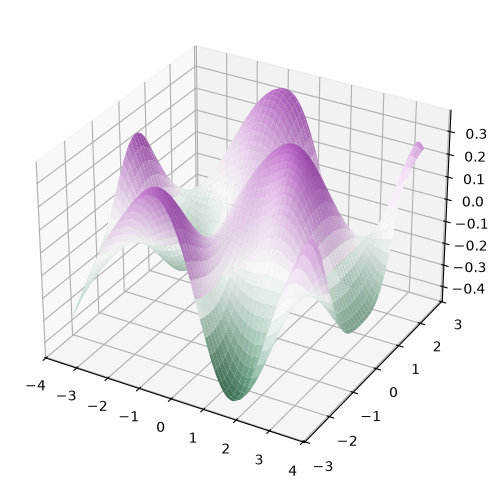

In [6]:
grid_pts = get_grid_pts(get_bounds(X_high[:,:2], margin=0.05), n_pts=100)
X_plt = grid_pts[:,0].reshape(100,100)
Y_plt = grid_pts[:,1].reshape(100,100)

# A smooth "potato-chip" surface with a few broad features
Z_plt = (
    0.38 * torch.sin(1.15 * X_plt + 0.35 * torch.cos(Y_plt))
    * torch.cos(1.25 * Y_plt)
    + 0.16 * torch.exp(-((X_plt + 1.1) ** 2 + (Y_plt - 0.35) ** 2) / 0.65)
    - 0.20 * torch.exp(-((X_plt - 0.85) ** 2 + (Y_plt + 0.55) ** 2) / 0.55)
    + 0.07 * torch.cos(0.8 * X_plt * Y_plt)
)

fig = plt.figure(figsize=(18,6))
ax = fig.add_subplot(1, 1, 1, projection="3d")
plot_surface(X_plt.numpy(),Y_plt.numpy(),Z_plt.numpy(),ax,use_wireframe=False)

In [7]:
edges = get_knn_graph(X_high, n_neighbors=10,device="cpu")
print(f"Found {edges.shape[0]} edges in the KNN graph.")
dst_edges = construct_distance_matrix(X_high.requires_grad_(True), edges, randers_metric,use_approx=True)

Found 34324 edges in the KNN graph.


Computing Randers distances: 100%|██████████| 344/344 [00:00<00:00, 1310.65it/s]


In [8]:
epsilon = compute_epsilon_empirical(dst_edges, scale=eps_scale)
distance_matrix = torch.full(
    (N, N), torch.finfo(X_high.dtype).max, dtype=X_high.dtype
)
distance_matrix[edges[:, 0], edges[:, 1]] = dst_edges
results = from_points(
    X_high,
    distances=distance_matrix,
    bandwidth=epsilon,
    n_components=m,
    embedding="isomap",
    embedding_params={"n_neighbors": 10},
)
X_low = results.coordinates
bounds = get_bounds(X_low, margin=0.3)


In [9]:
V = results.drift
V_normed = V / (results.drift_norm_squared.sqrt() + 1e-12).unsqueeze(1)
unit_V = V / (V.norm(dim=1, keepdim=True) + 1e-12)

In [10]:
# Sort by x coords for display
idx = torch.argsort(X_low[:, 0])
X_low_plt = X_low[idx].clone().detach()
V_plt = V[idx].clone().detach()
unit_V_plt = unit_V[idx].clone()
z_plt = Z[idx]

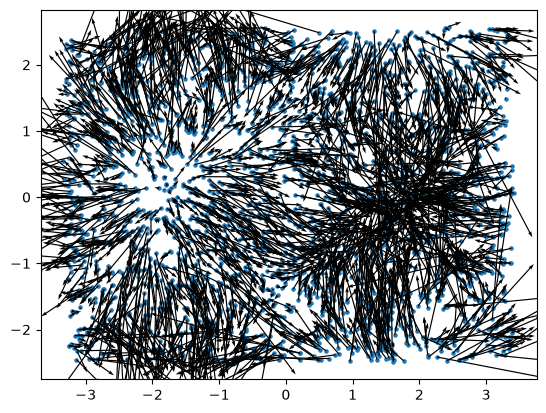

In [11]:
cbar = plt.scatter(
    X_low_plt[:, 0], X_low_plt[:, 1],s=5
)
skip=1
plt.quiver(
    X_low_plt[::skip, 0],
    X_low_plt[::skip, 1],
    # unit_V_plt[::skip, 0],
    # unit_V_plt[::skip, 1],
    V_plt[::skip, 0],
    V_plt[::skip, 1],
    color="black",
    scale=1,
    angles="xy",
    scale_units="xy",
    # alpha = results.admissible[idx][::skip].float().sigmoid()
)

In [12]:
unit_V = unit_V.clone().detach()
model, loss_list = interpolate_V(X_low, unit_V, dim=m)

Interpolating V: 100%|██████████| 500/500 [00:02<00:00, 201.64it/s, loss=0.106]


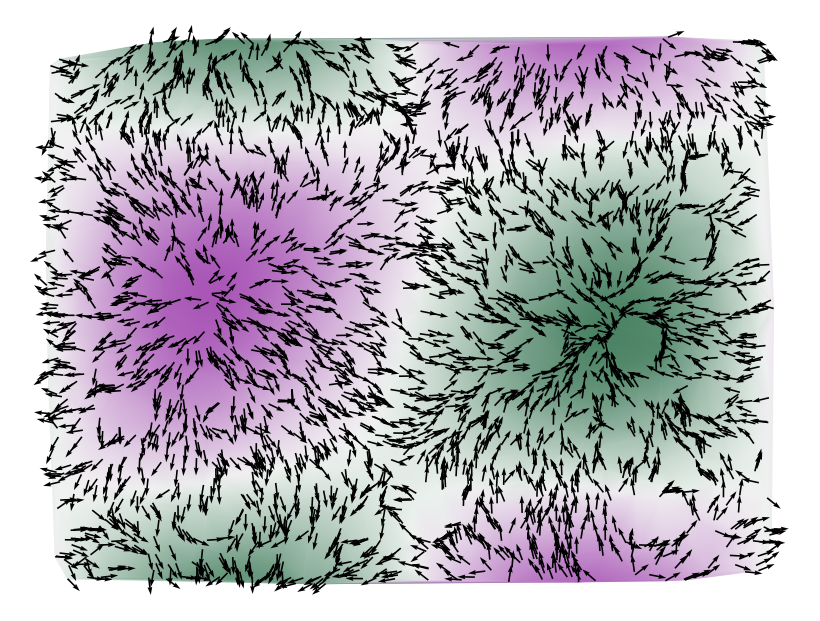

In [18]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

# Plot directly in the embedding coordinates returned by from_points.
# Triangular interpolation provides a smooth background without an
# out-of-sample embedding transform.
points = X_low.detach().cpu().numpy()
field = unit_V.detach().cpu().numpy()
heights = Z.detach().cpu().numpy().reshape(-1)
tri = mtri.Triangulation(points[:, 0], points[:, 1])

fig, ax = plt.subplots(figsize=(8, 8))
ax.tripcolor(
    tri,
    heights,
    cmap=cmap,
    shading="gouraud",
)

arrow_length = 0.12 * max(
    float(points[:, 0].max() - points[:, 0].min()),
    float(points[:, 1].max() - points[:, 1].min()),
)
ax.quiver(
    points[:, 0],
    points[:, 1],
    arrow_length * field[:, 0],
    arrow_length * field[:, 1],
    color="black",
    angles="xy",
    scale_units="xy",
    scale=5,
    width=0.002,
    pivot="tail",
)

ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout(pad=0)
plt.savefig("matsumoto_vector_field.pdf", bbox_inches="tight", pad_inches=0)
plt.show()


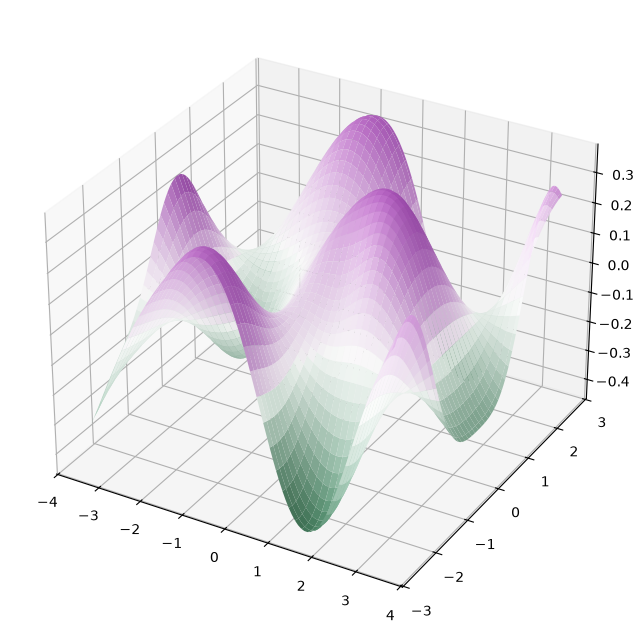

In [14]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1, projection="3d")
plot_surface(X_plt.numpy(),Y_plt.numpy(),Z_plt.numpy(),ax,use_wireframe=False)
fig.savefig("matsumoto_surface.pdf", bbox_inches="tight", pad_inches=0)

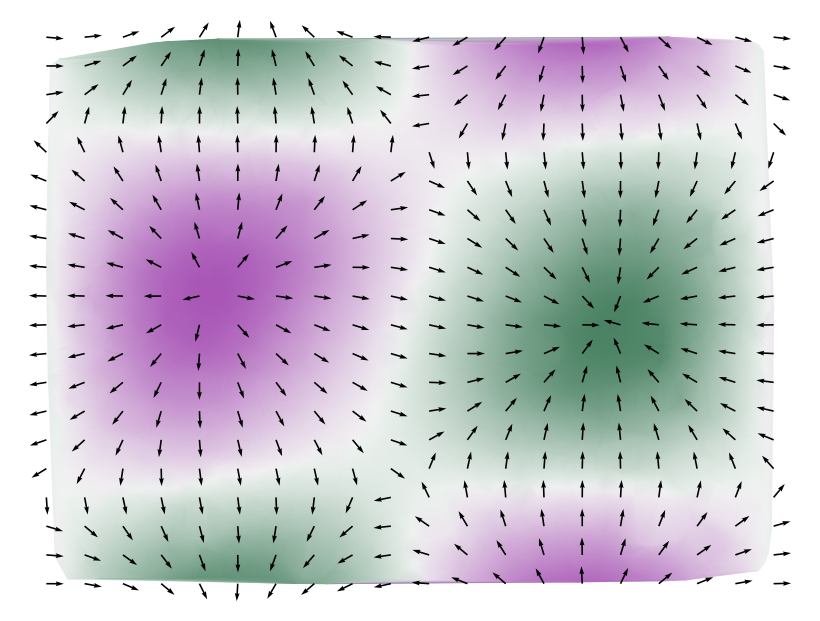

In [17]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

# Same interpolated background, with arrows evaluated on a regular embedding grid.
points = X_low.detach().cpu().numpy()
heights = Z.detach().cpu().numpy().reshape(-1)
tri = mtri.Triangulation(points[:, 0], points[:, 1])

n_arrows = 20
x_grid = torch.linspace(X_low[:, 0].min(), X_low[:, 0].max(), n_arrows)
y_grid = torch.linspace(X_low[:, 1].min(), X_low[:, 1].max(), n_arrows)
grid_x, grid_y = torch.meshgrid(x_grid, y_grid, indexing="ij")
grid_points = torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)

with torch.no_grad():
    grid_field = model(grid_points)
grid_field = grid_field / (grid_field.norm(dim=1, keepdim=True) + 1e-12)

fig, ax = plt.subplots(figsize=(8, 8))
ax.tripcolor(
    tri,
    heights,
    cmap=cmap,
    shading="gouraud",
)

arrow_length = 0.12 * max(
    float(points[:, 0].max() - points[:, 0].min()),
    float(points[:, 1].max() - points[:, 1].min()),
)
ax.quiver(
    grid_points[:, 0],
    grid_points[:, 1],
    arrow_length * grid_field[:, 0],
    arrow_length * grid_field[:, 1],
    color="black",
    angles="xy",
    scale_units="xy",
    scale=5,
    width=0.002,
    pivot="tail",
)

ax.set_aspect("equal")
ax.axis("off")
plt.tight_layout(pad=0)
plt.savefig("matsumoto_vector_field_grid.pdf", bbox_inches="tight", pad_inches=0)
plt.show()
